In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D

# Đường dẫn tới file CSV
CSV_PATH = "../../outputs_evaluation/aggregated_k_shot_detailed.csv"

_df = pd.read_csv(CSV_PATH)
_df['Shots_Int'] = _df['Shots'].str.extract(r'(\d+)').astype(int)
_df['Pair'] = _df['Source'] + " ➔ " + _df['Target']

In [33]:
def plot_by_targets(config_list, protocol, title_suffix="", show_plots=True):
    configs = [tuple(item.split("/")) for item in config_list]
    config_names = [f"{m} ({b})" for m, b in configs]

    df_filtered = _df[_df['Protocol'] == protocol].copy()
    df_filtered['Config'] = df_filtered['Method'] + " (" + df_filtered['Backbone'] + ")"
    df_filtered = df_filtered[df_filtered['Config'].isin(config_names)]

    if df_filtered.empty:
        print(f"⚠️ Không có dữ liệu cho các cấu hình: {config_list} trong {protocol}")
        return

    valid_pairs = [p for p in df_filtered['Pair'].unique() if len(df_filtered[df_filtered['Pair'] == p]['Shots_Int'].unique()) >= 3]
    if not valid_pairs:
        return

    # Cột là Target, Hàng là Source
    targets = sorted(list(set([p.split(" ➔ ")[1] for p in valid_pairs])))
    n_cols = len(targets)

    target_counts = {tgt: 0 for tgt in targets}
    for p in valid_pairs:
        target_counts[p.split(" ➔ ")[1]] += 1
    n_rows = max(target_counts.values())

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.2 * n_rows + 2.5), sharey=True)
    axes = np.atleast_2d(axes)
    if axes.shape[1] != n_cols:
        axes = axes.T

    HIGH_CONTRAST_COLORS = ["#E63946", "#1D3557", "#2A9D8F", "#F4A261", "#8338EC", "#FF006E"]
    palette = HIGH_CONTRAST_COLORS[:len(config_names)]
    MARKERS = ['o', 's', 'v', 'D', '^', 'P']
    row_counters = {tgt: 0 for tgt in targets}

    # Sắp xếp cặp theo Target (cột) -> Source (hàng)
    valid_pairs.sort(key=lambda x: (x.split(" ➔ ")[1], x.split(" ➔ ")[0]))

    for pair in valid_pairs:
        src, tgt = pair.split(" ➔ ")
        col_idx = targets.index(tgt)
        row_idx = row_counters[tgt]

        ax = axes[row_idx, col_idx]
        df_pair = df_filtered[df_filtered['Pair'] == pair]

        sns.lineplot(
            data=df_pair, x='Shots_Int', y='F1_Mean', hue='Config',
            style='Config', markers=MARKERS[:len(config_names)], dashes=False,
            linewidth=2, markersize=7, ax=ax, legend=False,
            palette=dict(zip(config_names, palette)), hue_order=config_names, style_order=config_names
        )

        ax.set_title(f'{pair}', fontsize=11, fontweight='bold', pad=10)
        ax.set_xlabel('Số lượng K-Shot' if row_idx == n_rows - 1 else '', fontsize=9)
        ax.set_ylabel('Macro F1-Score (%)' if col_idx == 0 else '', fontsize=9)
        ax.set_xticks(sorted(df_pair['Shots_Int'].unique()))
        ax.set_ylim(10, 100)
        ax.grid(True, linestyle='--', alpha=0.6)

        row_counters[tgt] += 1

    # Ẩn các ô trống
    for col_idx, tgt in enumerate(targets):
        for row_idx in range(row_counters[tgt], n_rows):
            axes[row_idx, col_idx].axis('off')

    fig.suptitle(f'So sánh F1-Score (Cột: Target - {protocol} - {title_suffix})', fontsize=18, fontweight='bold', y=0.97)

    custom_lines = [Line2D([0], [0], color=palette[idx], lw=2, marker=MARKERS[idx]) for idx in range(len(config_names))]
    fig.legend(custom_lines, config_names, title='Cấu hình', loc='upper center', bbox_to_anchor=(0.5, 0.92),
               ncol=len(config_names), fontsize=11, title_fontsize=12, frameon=True, borderpad=0.6, columnspacing=2.0)

    plt.subplots_adjust(top=0.80, bottom=0.08, left=0.06, right=0.98, wspace=0.18, hspace=0.45)
    if show_plots: plt.show()
    else: plt.close(fig)


def plot_by_sources(config_list, protocol, title_suffix="", show_plots=True):
    configs = [tuple(item.split("/")) for item in config_list]
    config_names = [f"{m} ({b})" for m, b in configs]

    df_filtered = _df[_df['Protocol'] == protocol].copy()
    df_filtered['Config'] = df_filtered['Method'] + " (" + df_filtered['Backbone'] + ")"
    df_filtered = df_filtered[df_filtered['Config'].isin(config_names)]

    if df_filtered.empty:
        print(f"⚠️ Không có dữ liệu cho các cấu hình: {config_list} trong {protocol}")
        return

    valid_pairs = [p for p in df_filtered['Pair'].unique() if len(df_filtered[df_filtered['Pair'] == p]['Shots_Int'].unique()) >= 3]
    if not valid_pairs:
        return

    # Cột là Source, Hàng là Target
    sources = sorted(list(set([p.split(" ➔ ")[0] for p in valid_pairs])))
    n_cols = len(sources)

    source_counts = {src: 0 for src in sources}
    for p in valid_pairs:
        source_counts[p.split(" ➔ ")[0]] += 1
    n_rows = max(source_counts.values())

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.2 * n_rows + 2.5), sharey=True)
    axes = np.atleast_2d(axes)
    if axes.shape[1] != n_cols:
        axes = axes.T

    HIGH_CONTRAST_COLORS = ["#E63946", "#1D3557", "#2A9D8F", "#F4A261", "#8338EC", "#FF006E"]
    palette = HIGH_CONTRAST_COLORS[:len(config_names)]
    MARKERS = ['o', 's', 'v', 'D', '^', 'P']
    row_counters = {src: 0 for src in sources}

    # Sắp xếp cặp theo Source (cột) -> Target (hàng)
    valid_pairs.sort(key=lambda x: (x.split(" ➔ ")[0], x.split(" ➔ ")[1]))

    for pair in valid_pairs:
        src, tgt = pair.split(" ➔ ")
        col_idx = sources.index(src)
        row_idx = row_counters[src]

        ax = axes[row_idx, col_idx]
        df_pair = df_filtered[df_filtered['Pair'] == pair]

        sns.lineplot(
            data=df_pair, x='Shots_Int', y='F1_Mean', hue='Config',
            style='Config', markers=MARKERS[:len(config_names)], dashes=False,
            linewidth=2, markersize=7, ax=ax, legend=False,
            palette=dict(zip(config_names, palette)), hue_order=config_names, style_order=config_names
        )

        ax.set_title(f'{pair}', fontsize=11, fontweight='bold', pad=10)
        ax.set_xlabel('Số lượng K-Shot' if row_idx == n_rows - 1 else '', fontsize=9)
        ax.set_ylabel('Macro F1-Score (%)' if col_idx == 0 else '', fontsize=9)
        ax.set_xticks(sorted(df_pair['Shots_Int'].unique()))
        ax.set_ylim(10, 100)
        ax.grid(True, linestyle='--', alpha=0.6)

        row_counters[src] += 1

    # Ẩn các ô trống
    for col_idx, src in enumerate(sources):
        for row_idx in range(row_counters[src], n_rows):
            axes[row_idx, col_idx].axis('off')

    fig.suptitle(f'So sánh F1-Score (Cột: Source - {protocol} - {title_suffix})', fontsize=18, fontweight='bold', y=0.97)

    custom_lines = [Line2D([0], [0], color=palette[idx], lw=2, marker=MARKERS[idx]) for idx in range(len(config_names))]
    fig.legend(custom_lines, config_names, title='Cấu hình', loc='upper center', bbox_to_anchor=(0.5, 0.92),
               ncol=len(config_names), fontsize=11, title_fontsize=12, frameon=True, borderpad=0.6, columnspacing=2.0)

    plt.subplots_adjust(top=0.80, bottom=0.08, left=0.06, right=0.98, wspace=0.18, hspace=0.45)
    if show_plots: plt.show()
    else: plt.close(fig)

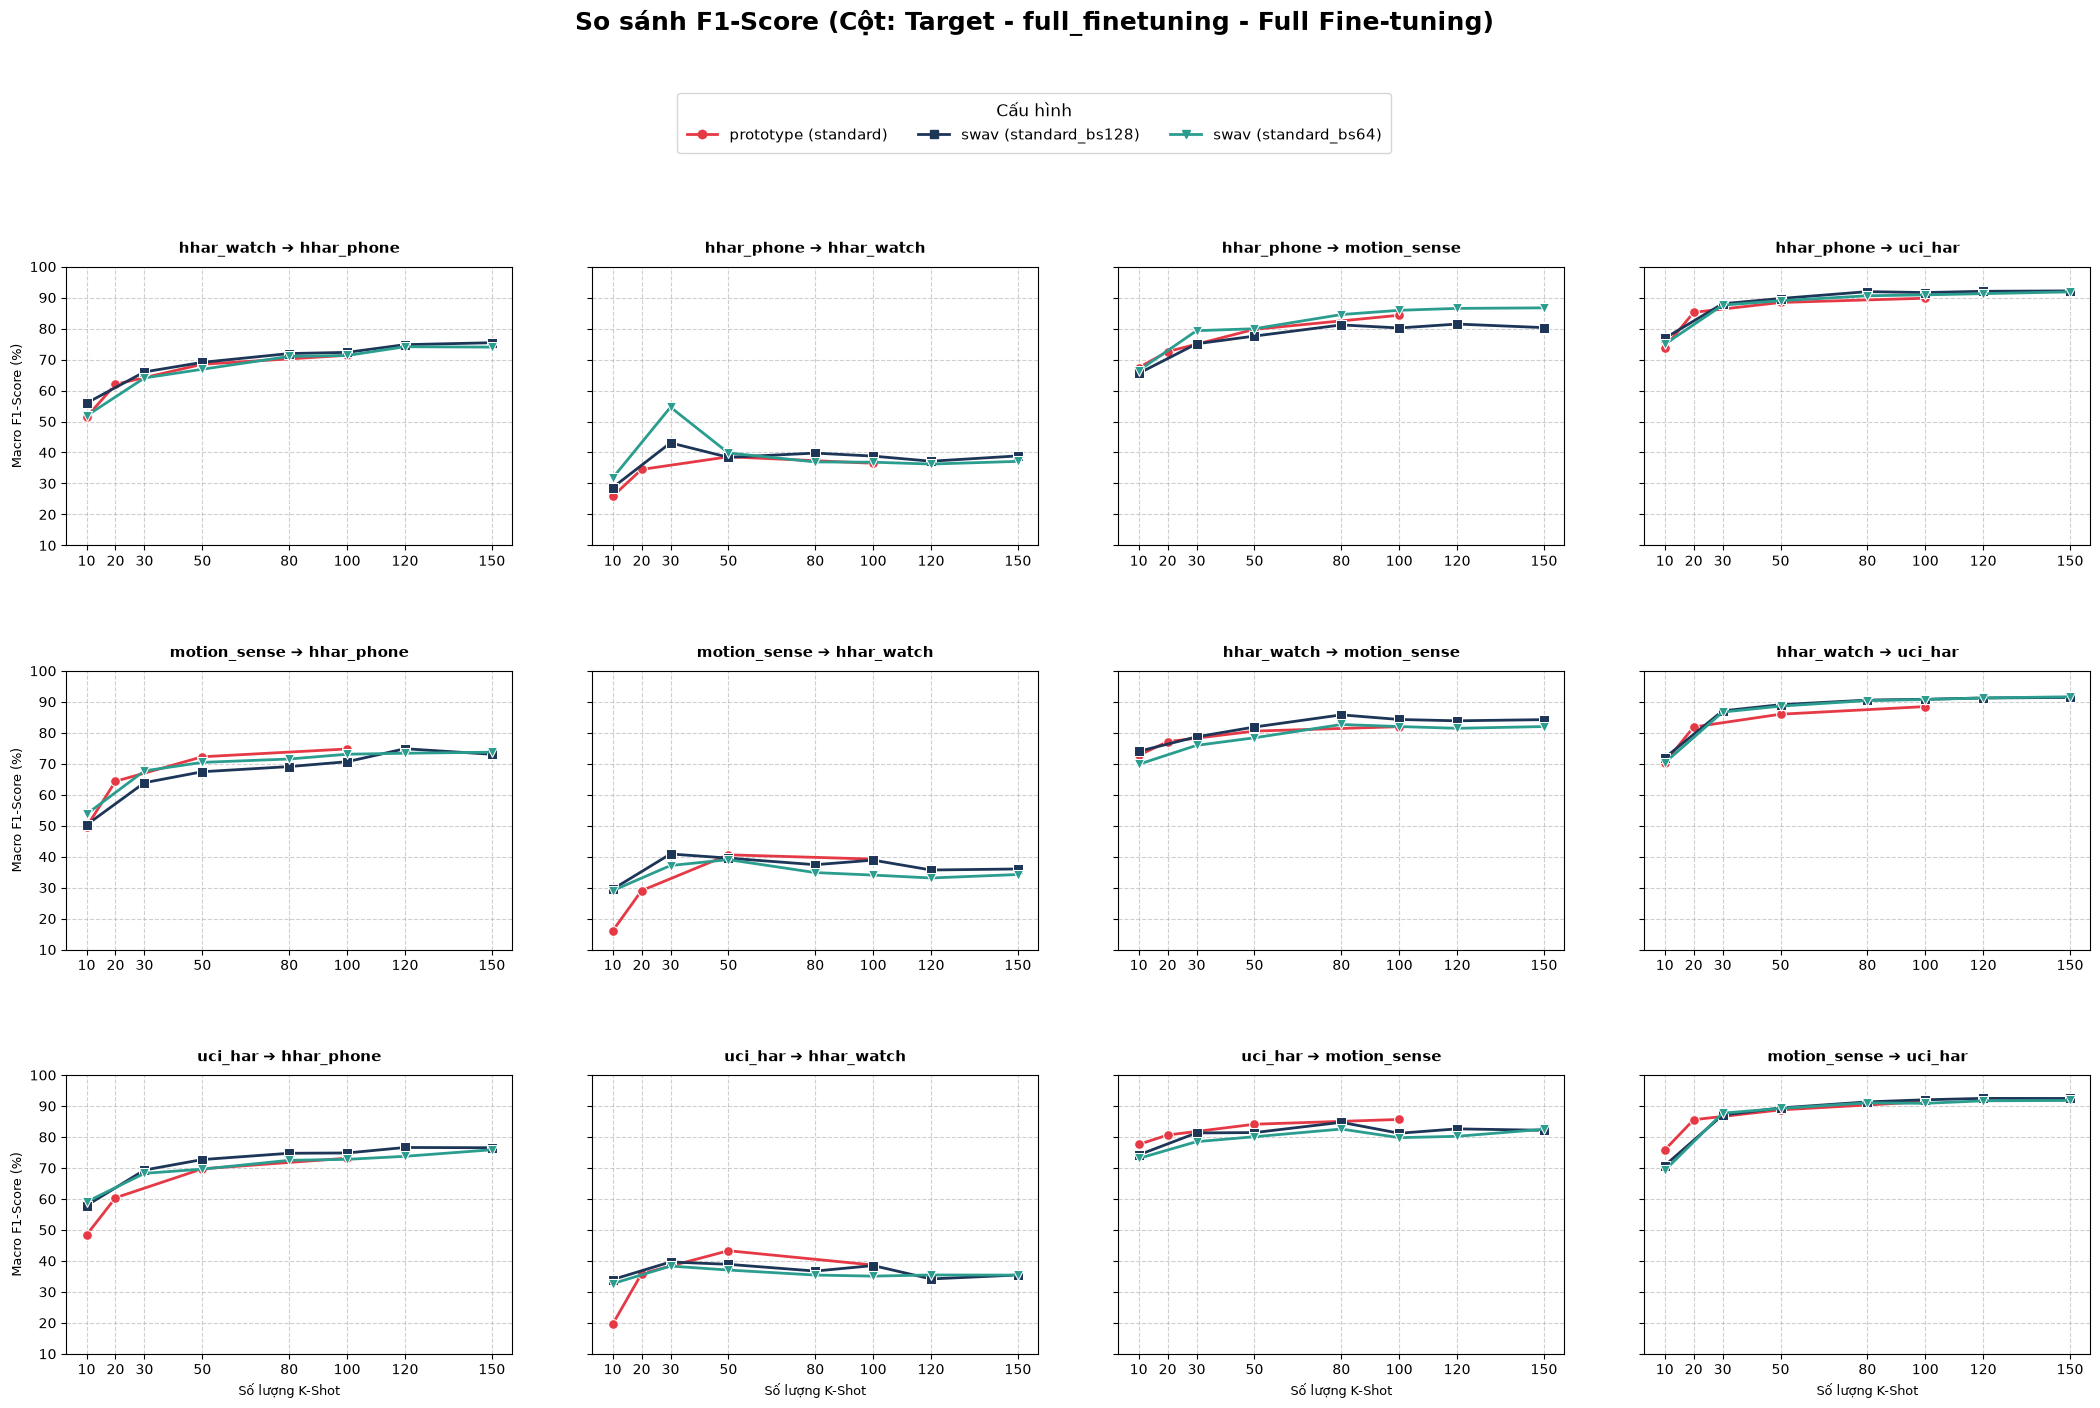

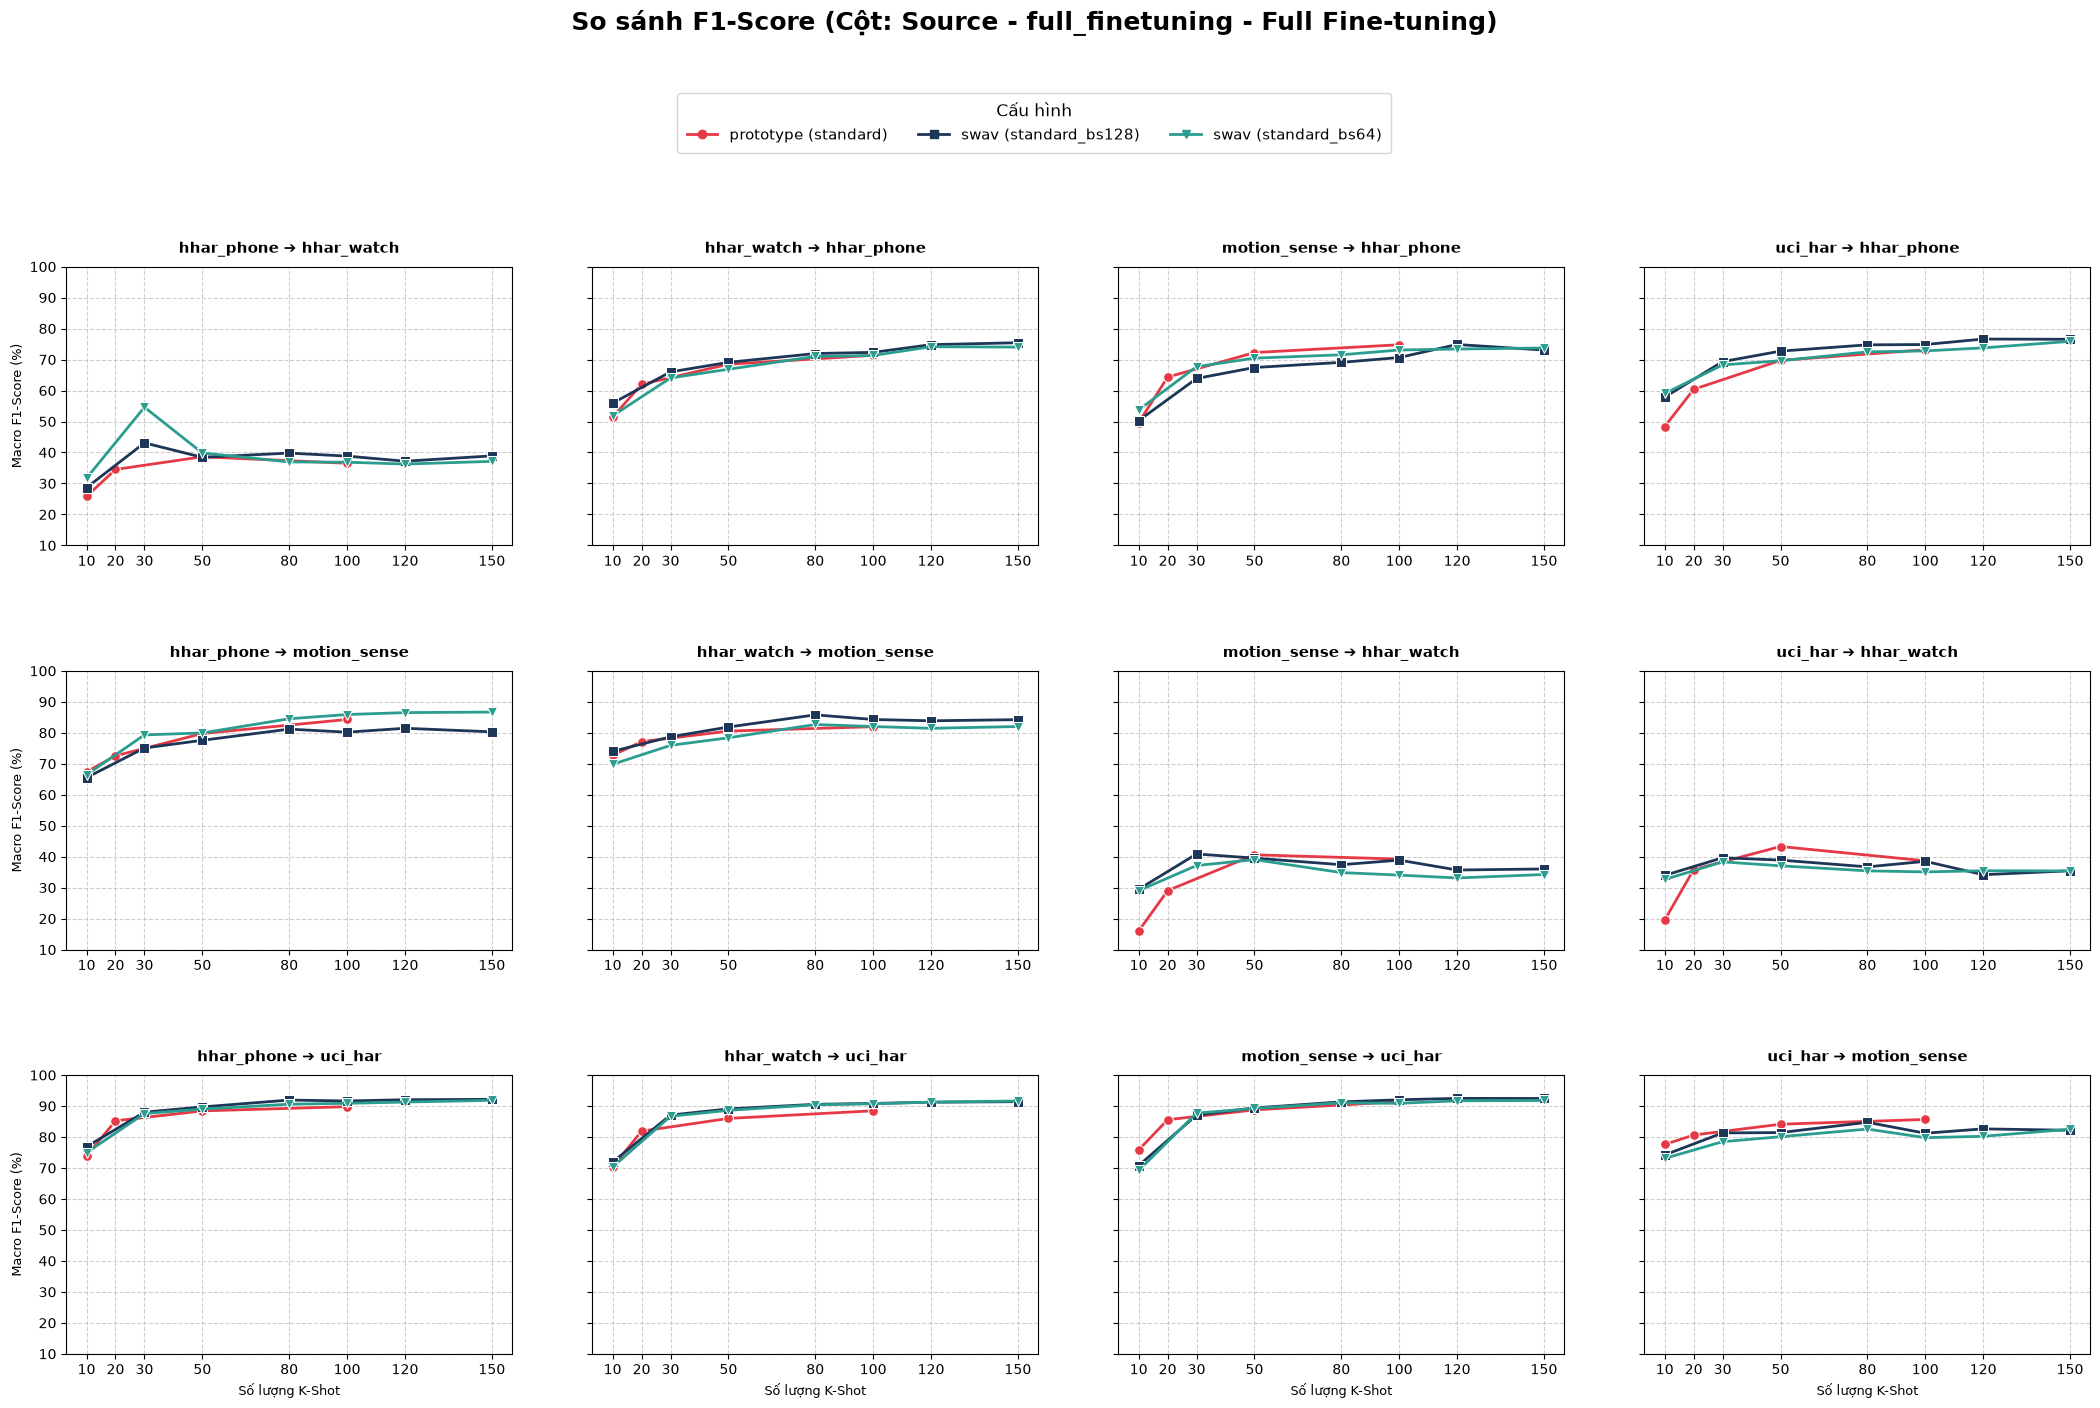

In [34]:
# Gọi hàm 1: Nhóm theo Đích (Target)
plot_by_targets(
    config_list=["prototype/standard", "swav/standard_bs128", "swav/standard_bs64"],
    protocol="full_finetuning",
    title_suffix="Full Fine-tuning"
)

# Gọi hàm 2: Nhóm theo Nguồn (Source)
plot_by_sources(
    config_list=["prototype/standard", "swav/standard_bs128", "swav/standard_bs64"],
    protocol="full_finetuning",
    title_suffix="Full Fine-tuning"
)